# AI 2 — Phase 4.0: NTD data inventory and go/no-go

**Question.** How many years of bus fuel data does each US agency have? This decides the AI 2 design
(implementation plan, Phase 4.0): **7+ years → full model** (1–2 years ahead, several backtest windows),
**3–4 years → reduced design** (1–2 years ahead on the miles × intensity split).

**Checks**
1. Inventory: which NTD files exist, years, rows, hashes.
2. Year labels and schema: is each file really the report year its folder says? Do old (2015–2021) and new (2022+) tables join?
3. Years of bus fuel per agency (the go/no-go count).
4. Joins: fuel ↔ service (TS2.1 VRM) ↔ fleet (vehicle inventory) for the same agency-year.
5. Units and continuity: CNG unit, miles per gallon, jumps at the 2021→2022 format change, fuel-miles vs. revenue miles.
6. MBTA (NTD ID 10003) worked example.

Inputs are the harmonised tables written by `src/ntd/io.py` (`python -m src.ntd.io`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src" / "ntd").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.ntd import io as ntd

OUT = ROOT / "data" / "interim" / "ai2_phase4_0"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
DOCFIG = ROOT / "docs" / "figures"; DOCFIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40)

def savefig(fig, name):
    fig.tight_layout()
    for d in (FIG, DOCFIG):
        fig.savefig(d / f"ai2_{name}.png", dpi=130)
    plt.show()

paths = {n: ntd.INTERIM / f"{n}.parquet" for n in ("fuel_energy", "vehicle_inventory", "service")}
if not all(p.exists() for p in paths.values()):
    ntd.build_interim()
fe = pd.read_parquet(paths["fuel_energy"])
rvi = pd.read_parquet(paths["vehicle_inventory"])
sv = pd.read_parquet(paths["service"])
print({k: len(v) for k, v in dict(fuel=fe, rvi=rvi, service=sv).items()})

{'fuel': 13871, 'rvi': 278223, 'service': 191636}


## 1. Inventory of raw files

In [2]:
rows = []
for name, p in paths.items():
    for f, h in ntd.source_hashes(p).items():
        rows.append(dict(table=name, file=f, sha256=h[:12]))
inv_files = pd.DataFrame(rows)
inv_files.to_csv(OUT / "raw_file_hashes.csv", index=False)

inv = pd.DataFrame({
    "Fuel and Energy": fe.groupby("report_year").agg(rows=("ntd_id", "size"), agencies=("ntd_id", "nunique")).apply(tuple, axis=1),
    "Vehicle inventory": rvi.groupby("report_year").agg(rows=("rvi_id", "size"), agencies=("ntd_id", "nunique")).apply(tuple, axis=1),
    "TS2.1 service (VRM>0)": sv[sv.vrm > 0].groupby("year").agg(rows=("ntd_id", "size"), agencies=("ntd_id", "nunique")).apply(tuple, axis=1),
})
inv.index.name = "year"
print(inv.loc[2010:].to_string())

     Fuel and Energy Vehicle inventory TS2.1 service (VRM>0)
year                                                        
2010             NaN               NaN          (2866, 1858)
2011             NaN               NaN          (3079, 1953)
2012             NaN               NaN          (3308, 2056)
2013             NaN               NaN          (3422, 2096)
2014             NaN               NaN          (3453, 2112)
2015     (1238, 533)      (16997, 950)          (3517, 2138)
2016     (1251, 535)     (17401, 1030)          (3680, 2220)
2017     (1253, 536)     (17744, 1035)          (3705, 2225)
2018     (1244, 529)     (19398, 1042)          (3693, 2204)
2019     (1236, 520)     (19671, 1024)          (3677, 2181)
2020     (1316, 523)     (20236, 1043)          (3711, 2212)
2021     (1315, 528)     (20338, 1057)          (3648, 2219)
2022     (1267, 527)     (35681, 2766)          (3661, 2205)
2023     (1237, 521)     (36107, 2654)          (3672, 2200)
2024     (1255, 524)    

## 2. Year labels and schema
Each Fuel and Energy file reports `Mode VOMS` (peak vehicles) per agency × mode × type of service. TS2.1 reports
the same number per year, so a file whose VOMS matches TS2.1 in its own year — and not in the neighbouring
years — is labelled correctly.

In [3]:
m = fe.loc[fe.mode_voms > 0, ["ntd_id", "mode", "tos", "report_year", "mode_voms"]]
label = {}
for shift, nm in [(-1, "TS2.1 year − 1"), (0, "TS2.1 same year"), (1, "TS2.1 year + 1")]:
    s = sv[["ntd_id", "mode", "tos", "year", "voms"]].assign(report_year=lambda d: d.year - shift)
    j = m.merge(s, on=["ntd_id", "mode", "tos", "report_year"])
    label[nm] = j.assign(eq=j.mode_voms == j.voms).groupby("report_year").eq.mean()
label = pd.DataFrame(label).round(3)
label.to_csv(OUT / "year_label_check.csv")
print(label.to_string())

qty = ntd.QTY_COLS
schema = fe.groupby("report_year")[qty + ["miles_dual_fuel", "reporter_type"]].apply(lambda g: g.notna().any()).T
print(schema.replace({True: "yes", False: "—"}).to_string())

             TS2.1 year − 1  TS2.1 same year  TS2.1 year + 1
report_year                                                 
2015                  0.479              1.0           0.483
2016                  0.478              1.0           0.501
2017                  0.497              1.0           0.479
2018                  0.479              1.0           0.433
2019                  0.432              1.0           0.468
2020                  0.460              1.0           0.275
2021                  0.280              1.0           0.374
2022                  0.368              1.0           0.395
2023                  0.404              1.0           0.422
2024                  0.421              1.0           0.424
2025                  0.424              1.0             NaN


report_year     2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025
diesel_gal       yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
gasoline_gal     yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
lpg_gal          yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
cng_gal          yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
biodiesel_gal    yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
hydrogen_kg        —    —    —    —    —    —    —  yes  yes  yes  yes
other_gal        yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
elec_prop_kwh    yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
elec_batt_kwh    yes  yes  yes  yes  yes  yes  yes  yes  yes  yes  yes
miles_dual_fuel    —    —    —    —    —    —    —    —    —    —  yes
reporter_type    yes  yes  yes  yes  yes    —  yes  yes  yes  yes  yes


## 3. Bus agency-year table and years of fuel data
Bus = NTD modes MB (bus) and RB (bus rapid transit), directly operated and purchased transportation combined.
Commuter bus (CB) is kept apart, as the plan says. CO₂ uses the EPA factors from the AI 3 doc (April 2022):
diesel 10.21 kg/gal, gasoline 8.78 kg/gal, LPG 5.68 kg/gal, CNG 0.05444 kg/scf. CNG is reported in gallon
equivalents; the default here is the gasoline gallon equivalent (123.57 scf, DOE AFDC) — section 5 checks this.
Biodiesel (B100, 9.45 kg/gal) is **included** in tailpipe CO₂: agencies switch diesel gallons between the
"diesel" and "bio-diesel" columns from year to year (MBTA reported 5.6 M gal as biodiesel in 2019 and as diesel
in every other year), so leaving it out would create fake 75% drops. Fossil-only CO₂ is kept as a side column.
"Other fuel" is counted at the diesel factor: for buses it is mostly renewable diesel (TriMet from 2023,
Community Transit from 2024 report all their bus fuel there), which burns like diesel at the tailpipe.
Electricity is kWh only (zero tailpipe).

In [4]:
EF = {"diesel_gal": 10.21, "gasoline_gal": 8.78, "lpg_gal": 5.68, "cng_gal": 0.05444 * 123.57}
EF_BIO = 9.45
EF_OTHER = 10.21  # assumption: renewable diesel ~ diesel at the tailpipe
CNG_DGE_SCF = 139.0  # sensitivity: diesel gallon equivalent (6.31-6.38 lb CNG)

miles_cols = [f"miles_{f}" for f in ntd.MILES_FUELS]

def agency_year(df):
    d = df.copy()
    d[qty + miles_cols] = d[qty + miles_cols].fillna(0)
    g = d.groupby(["ntd_id", "report_year"]).agg(
        agency=("agency", "last"), state=("state", "last"), mode_voms=("mode_voms", "sum"),
        n_rows=("mode", "size"), modes=("mode", lambda s: "+".join(sorted(set(s)))),
        any_flag=("any_flag", "max"), **{c: (c, "sum") for c in qty + miles_cols})
    g["co2_fossil_t"] = sum(g[c] * f for c, f in EF.items()) / 1000
    g["co2_bio_t"] = g["biodiesel_gal"] * EF_BIO / 1000
    g["co2_other_t"] = g["other_gal"] * EF_OTHER / 1000
    g["co2_t"] = g["co2_fossil_t"] + g["co2_bio_t"] + g["co2_other_t"]   # tailpipe CO2: the AI 2 target
    g["co2_dge_t"] = g["co2_t"] + g["cng_gal"] * 0.05444 * (CNG_DGE_SCF - 123.57) / 1000
    g["fuel_miles"] = g[miles_cols].sum(axis=1)
    g["has_fuel"] = (g[["diesel_gal", "gasoline_gal", "lpg_gal", "cng_gal", "biodiesel_gal", "other_gal",
                        "hydrogen_kg", "elec_batt_kwh", "elec_prop_kwh"]] > 0).any(axis=1)
    g["intensity_kg_mi"] = g.co2_t * 1000 / g.fuel_miles.replace(0, np.nan)   # per total (fuel-table) mile
    return g.reset_index()

bus = agency_year(fe[fe["mode"].isin(["MB", "RB"])])
cb = agency_year(fe[fe["mode"] == "CB"])
bus_f = bus[bus.has_fuel]
print("bus agency-years with fuel:", len(bus_f), " agencies:", bus_f.ntd_id.nunique())
print(bus_f.groupby("report_year").agg(agencies=("ntd_id", "nunique"), co2_Mt=("co2_t", lambda s: s.sum() / 1e6)).round(3).T.to_string())

bus agency-years with fuel: 4605  agencies: 478
report_year     2015     2016     2017     2018     2019     2020     2021     2022     2023     2024     2025
agencies     428.000  430.000  428.000  422.000  416.000  416.000  415.000  407.000  411.000  417.000  415.000
co2_Mt         5.114    5.296    5.186    5.059    5.039    4.382    4.135    4.162    4.279    4.391    4.488


          agencies  share  share_of_2025_CO2
n_years                                     
1–2             36  0.075              0.014
3–4             20  0.042              0.007
5–6             13  0.027              0.002
7–10            46  0.096              0.015
11 (all)       363  0.759              0.963
agencies with >= 7 years: 409 | with a >= 7-year unbroken run: 403


/tmp/ipykernel_63310/3040687053.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dist["share_of_2025_CO2"] = per_agency.groupby(bins).co2_t_last.sum().div(per_agency.co2_t_last.sum()).round(3)


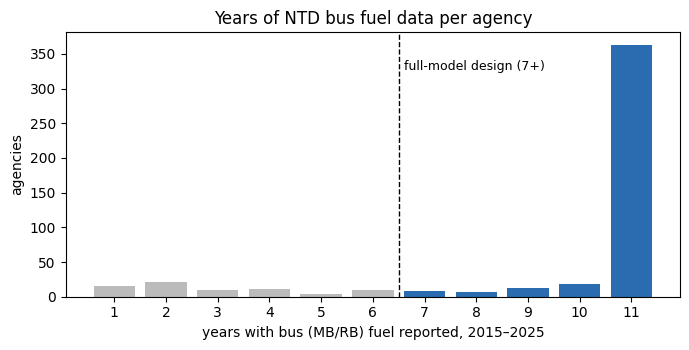

In [5]:
YEARS = sorted(fe.report_year.unique())
per_agency = bus_f.groupby("ntd_id").agg(
    agency=("agency", "last"), state=("state", "last"), n_years=("report_year", "nunique"),
    first=("report_year", "min"), last=("report_year", "max"), co2_t_last=("co2_t", "last"))

def longest_run(years):
    ys, best, cur = sorted(years), 1, 1
    for a, b in zip(ys, ys[1:]):
        cur = cur + 1 if b == a + 1 else 1
        best = max(best, cur)
    return best

per_agency["longest_run"] = bus_f.groupby("ntd_id").report_year.apply(longest_run)
per_agency["has_2022_onward_all"] = bus_f[bus_f.report_year >= 2022].groupby("ntd_id").report_year.nunique().reindex(per_agency.index).fillna(0).eq(4)
per_agency.to_csv(OUT / "years_of_fuel_per_agency.csv")

bins = pd.cut(per_agency.n_years, [0, 2, 4, 6, 10, 11], labels=["1–2", "3–4", "5–6", "7–10", "11 (all)"])
dist = pd.DataFrame({"agencies": bins.value_counts().sort_index()})
dist["share"] = (dist.agencies / dist.agencies.sum()).round(3)
dist["share_of_2025_CO2"] = per_agency.groupby(bins).co2_t_last.sum().div(per_agency.co2_t_last.sum()).round(3)
print(dist.to_string())
print("agencies with >= 7 years:", (per_agency.n_years >= 7).sum(), "| with a >= 7-year unbroken run:", (per_agency.longest_run >= 7).sum())

fig, ax = plt.subplots(figsize=(7, 3.6))
vc = per_agency.n_years.value_counts().sort_index()
ax.bar(vc.index, vc.values, color=["#bbb" if y < 7 else "#2b6cb0" for y in vc.index])
ax.axvline(6.5, color="k", ls="--", lw=1); ax.text(6.6, vc.max() * 0.9, "full-model design (7+)", fontsize=9)
ax.set_xlabel("years with bus (MB/RB) fuel reported, 2015–2025"); ax.set_ylabel("agencies")
ax.set_title("Years of NTD bus fuel data per agency"); ax.set_xticks(range(1, 12))
savefig(fig, "01_years_per_agency")

## 4. Joins: fuel ↔ service ↔ fleet in the same agency-year

In [6]:
svc_bus = (sv[sv["mode"].isin(["MB", "RB"])].groupby(["ntd_id", "year"])[["vrm", "vrh", "voms"]].sum(min_count=1)
           .reset_index().rename(columns={"year": "report_year"}))
rb = rvi[rvi["mode"].isin(["MB", "RB"])].drop_duplicates(["report_year", "ntd_id", "rvi_id"])
fleet = rb.groupby(["ntd_id", "report_year"]).apply(lambda g: pd.Series({
    "active_buses": g.active_fleet.sum(),
    "avg_age": (lambda h: np.average(h.report_year - h.manufacture_year, weights=h.active_fleet) if h.active_fleet.sum() > 0 else np.nan)(g.dropna(subset=["manufacture_year"])),
    "share_myr_missing": g.loc[g.manufacture_year.isna(), "active_fleet"].sum() / max(g.active_fleet.sum(), 1),
    "share_hybrid": g.loc[g.fuel_type.str.contains("Hybrid", na=False), "active_fleet"].sum() / max(g.active_fleet.sum(), 1),
    "share_cng": g.loc[g.fuel_type.str.contains("Natural Gas", na=False), "active_fleet"].sum() / max(g.active_fleet.sum(), 1),
    "share_bev": g.loc[g.fuel_type.eq("Electric Battery"), "active_fleet"].sum() / max(g.active_fleet.sum(), 1),
})).reset_index()

panel = bus_f.merge(svc_bus, on=["ntd_id", "report_year"], how="left").merge(fleet, on=["ntd_id", "report_year"], how="left")
panel["in_service"] = panel.vrm > 0
panel["in_fleet"] = panel.active_buses > 0
panel["complete"] = panel.in_service & panel.in_fleet
join = panel.groupby("report_year")[["in_service", "in_fleet", "complete"]].mean().round(3)
join["agency_years"] = panel.groupby("report_year").size()
print(join.to_string())

panel["small_lt10"] = panel.active_buses < 10
print("agency-years with < 10 active buses:", int(panel.small_lt10.sum()), f"({panel.small_lt10.mean():.1%})")
print("CO2 share of those:", round(panel.loc[panel.small_lt10, 'co2_t'].sum() / panel.co2_t.sum(), 4))
panel["intensity_kg_vrm"] = panel.co2_t * 1000 / panel.vrm
odd = panel[(panel.intensity_kg_vrm < 0.8) | (panel.intensity_kg_vrm > 8)]
print("agency-years with CO2 per revenue mile outside 0.8–8 kg (impossible or suspicious):", len(odd),
      f"({len(odd) / len(panel):.1%}); electric-heavy among them:", int((odd.elec_batt_kwh > 0).sum()))
print(odd.sort_values("intensity_kg_vrm")[["ntd_id", "agency", "report_year", "co2_t", "vrm", "intensity_kg_vrm", "elec_batt_kwh"]].head(12).round(3).to_string())

usable = panel[panel.complete & ~panel.small_lt10]
per_usable = usable.groupby("ntd_id").report_year.nunique()
print("usable agency-years (fuel+service+fleet, >= 10 buses):", len(usable), "| agencies:", per_usable.size,
      "| with >= 7 usable years:", int((per_usable >= 7).sum()))
panel.to_parquet(OUT / "bus_agency_year_preview.parquet", index=False)

             in_service  in_fleet  complete  agency_years
report_year                                              
2015                1.0     1.000     1.000           428
2016                1.0     0.998     0.998           430
2017                1.0     1.000     1.000           428
2018                1.0     1.000     1.000           422
2019                1.0     1.000     1.000           416
2020                1.0     1.000     1.000           416
2021                1.0     1.000     1.000           415
2022                1.0     1.000     1.000           407
2023                1.0     1.000     1.000           411
2024                1.0     1.000     1.000           417
2025                1.0     0.998     0.998           415
agency-years with < 10 active buses: 202 (4.4%)
CO2 share of those: 0.0012
agency-years with CO2 per revenue mile outside 0.8–8 kg (impossible or suspicious): 37 (0.8%); electric-heavy among them: 18
     ntd_id                                   

/tmp/ipykernel_63310/612191906.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fleet = rb.groupby(["ntd_id", "report_year"]).apply(lambda g: pd.Series({


## 5. Units and continuity
**CNG unit.** If CNG were in standard cubic feet, CNG buses would show about 0.03 miles per "gallon". In gallon
equivalents, CNG buses should get somewhat fewer miles per gallon equivalent than diesel buses (about 0.8–0.9 ×).
Miles per gallon is computed here for agencies whose bus fleet runs on a single fuel.

             diesel-only fleets: median mpg  CNG-only fleets: median mpg(e)  CNG agencies  ratio
report_year                                                                                     
2015                                   4.40                            3.03            25   0.69
2016                                   4.47                            3.10            29   0.69
2017                                   4.52                            3.12            29   0.69
2018                                   4.49                            3.14            30   0.70
2019                                   4.60                            3.07            31   0.67
2020                                   4.68                            3.26            33   0.70
2021                                   4.70                            3.06            34   0.65
2022                                   4.67                            3.25            36   0.70
2023                          

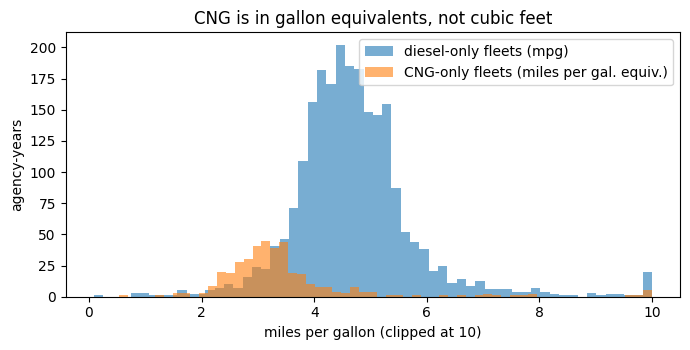

In [7]:
b = bus_f.copy()
tot_e = b[["diesel_gal", "biodiesel_gal", "gasoline_gal", "cng_gal", "lpg_gal"]].sum(axis=1)
b["mpg_diesel"] = b.miles_diesel / (b.diesel_gal + b.biodiesel_gal).replace(0, np.nan)
b["mpg_cng"] = b.miles_cng / b.cng_gal.replace(0, np.nan)
mono_d = b[((b.diesel_gal + b.biodiesel_gal) / tot_e > 0.95) & (b.miles_diesel > 1e5)]
mono_c = b[(b.cng_gal / tot_e > 0.95) & (b.miles_cng > 1e5)]
mpg = pd.DataFrame({"diesel-only fleets: median mpg": mono_d.groupby("report_year").mpg_diesel.median(),
                    "CNG-only fleets: median mpg(e)": mono_c.groupby("report_year").mpg_cng.median(),
                    "CNG agencies": mono_c.groupby("report_year").size()}).round(2)
mpg["ratio"] = (mpg.iloc[:, 1] / mpg.iloc[:, 0]).round(2)
print(mpg.to_string())

# same agency, both fuels in one year: per-agency ratio
both = b[(b.miles_cng > 1e5) & (b.miles_diesel > 1e5)]
print("agencies running both: median CNG/diesel mpg ratio =", round((both.mpg_cng / both.mpg_diesel).median(), 2), "n =", len(both))
b24 = b.query("report_year==2024")
print("CNG share of bus CO2 (2024):", round((b24.cng_gal * EF['cng_gal'] / 1000).sum() / b24.co2_t.sum(), 3),
      "| national CO2 change if DGE instead of GGE:", round(b24.co2_dge_t.sum() / b24.co2_t.sum() - 1, 4),
      "| for a CNG-only agency:", round(CNG_DGE_SCF / 123.57 - 1, 3))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(mono_d.mpg_diesel.clip(0, 10), bins=60, alpha=.6, label="diesel-only fleets (mpg)")
ax.hist(mono_c.mpg_cng.clip(0, 10), bins=60, alpha=.6, label="CNG-only fleets (miles per gal. equiv.)")
ax.set_xlabel("miles per gallon (clipped at 10)"); ax.set_ylabel("agency-years"); ax.legend()
ax.set_title("CNG is in gallon equivalents, not cubic feet")
savefig(fig, "02_mpg_cng_vs_diesel")

**Continuity.** For agencies present in consecutive years, the year-over-year change of bus CO₂ should look the
same across the 2021→2022 switch from Excel workbooks to the data portal; a unit or definition change would
show up as a shifted median or a burst of large jumps.

/home/omar-hazem/projects/Grad_project/transit-emissions-platform/venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


               n  median_change  share_jump_gt_50pct
report_year                                         
2016         417          0.009                0.050
2017         421         -0.005                0.040
2018         421         -0.000                0.026
2019         412         -0.010                0.022
2020         410         -0.111                0.071
2021         410         -0.035                0.054
2022         402          0.005                0.052
2023         398          0.007                0.043
2024         405          0.022                0.027
2025         410          0.017                0.044
             diesel_gal  biodiesel_gal  gasoline_gal  cng_gal  lpg_gal  elec_batt_kwh  fuel_miles  co2_t  co2_fossil_t  vrm_ts21
report_year                                                                                                                     
2015              343.7           39.8           8.3    147.9      7.6            3.0      2066.7    5.1  

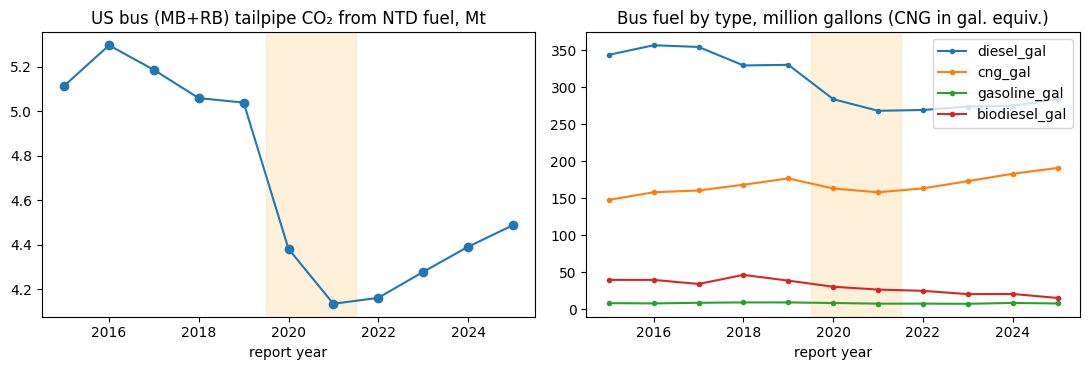

In [8]:
s = bus_f.set_index(["ntd_id", "report_year"]).co2_t
prev = s.groupby(level=0).shift(1)
yrs = s.index.get_level_values(1)
prev_year = pd.Series(yrs, index=s.index).groupby(level=0).shift(1)
r = np.log(s / prev)[(prev_year == yrs - 1) & (prev > 0) & (s > 0)]
cont = r.groupby(level=1).agg(n="size", median_change=lambda x: np.expm1(x.median()),
                             share_jump_gt_50pct=lambda x: (x.abs() > np.log(1.5)).mean()).round(3)
print(cont.to_string())

nat = bus_f.groupby("report_year")[["diesel_gal", "biodiesel_gal", "gasoline_gal", "cng_gal", "lpg_gal", "elec_batt_kwh", "fuel_miles", "co2_t", "co2_fossil_t"]].sum()
nat_svc = svc_bus[svc_bus.report_year.between(2015, 2025)].groupby("report_year").vrm.sum()
nat["vrm_ts21"] = nat_svc
print((nat / 1e6).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
(nat[["co2_t"]] / 1e6).plot(ax=axes[0], marker="o", legend=False)
axes[0].set_title("US bus (MB+RB) tailpipe CO₂ from NTD fuel, Mt"); axes[0].axvspan(2019.5, 2021.5, color="orange", alpha=.15)
(nat[["diesel_gal", "cng_gal", "gasoline_gal", "biodiesel_gal"]] / 1e6).plot(ax=axes[1], marker=".")
axes[1].set_title("Bus fuel by type, million gallons (CNG in gal. equiv.)"); axes[1].axvspan(2019.5, 2021.5, color="orange", alpha=.15)
for a in axes: a.set_xlabel("report year")
savefig(fig, "03_national_bus_fuel")

**Miles.** TS2.1 has no total vehicle miles (only revenue miles, VRM). The Fuel and Energy table reports miles
travelled by each fuel's vehicles, which should be total miles (revenue + deadhead) and so a bit above VRM.

In [9]:
pm = panel[panel.in_service & (panel.fuel_miles > 0)].copy()
pm["fuel_miles_over_vrm"] = pm.fuel_miles / pm.vrm
q = pm.groupby("report_year").fuel_miles_over_vrm.describe(percentiles=[.1, .5, .9])[["count", "10%", "50%", "90%"]].round(2)
q["share_below_0.95"] = pm.groupby("report_year").fuel_miles_over_vrm.apply(lambda x: (x < .95).mean()).round(3)
q["share_above_2"] = pm.groupby("report_year").fuel_miles_over_vrm.apply(lambda x: (x > 2).mean()).round(3)
print(q.to_string())

             count   10%   50%   90%  share_below_0.95  share_above_2
report_year                                                          
2015         424.0  1.00  1.10  1.36             0.061          0.031
2016         424.0  0.99  1.10  1.37             0.066          0.031
2017         424.0  1.01  1.11  1.39             0.052          0.038
2018         416.0  0.91  1.09  1.26             0.130          0.014
2019         376.0  0.96  1.09  1.30             0.093          0.029
2020         413.0  0.94  1.10  1.32             0.114          0.036
2021         406.0  0.86  1.07  1.24             0.172          0.000
2022         399.0  0.85  1.05  1.22             0.190          0.010
2023         403.0  0.85  1.07  1.22             0.169          0.005
2024         407.0  0.86  1.07  1.22             0.174          0.007
2025         404.0  0.89  1.07  1.23             0.141          0.002


## 6. MBTA (NTD ID 10003)

             modes  diesel_gal    cng_gal  elec_batt_kwh  elec_prop_kwh  biodiesel_gal      co2_t  fuel_miles         vrm  intensity_kg_vrm  active_buses  avg_age  share_hybrid  share_cng  share_bev
report_year                                                                                                                                                                                           
2015         MB+RB   5639631.0  4035185.0            0.0      9788210.0            0.0  84912.277  26819780.0  23138625.0             3.670        1079.0   10.684         0.000      0.335      0.000
2016         MB+RB   5456269.0  4144102.0            0.0      9907683.0            0.0  83822.705  26684343.0  24159324.0             3.470        1065.0   11.650         0.000      0.315      0.000
2017         MB+RB   5603711.0  3189466.0            0.0      8695719.0            0.0  78866.685  26723116.0  23113806.0             3.412        1330.0    9.362         0.000      0.347      0.000
2018 

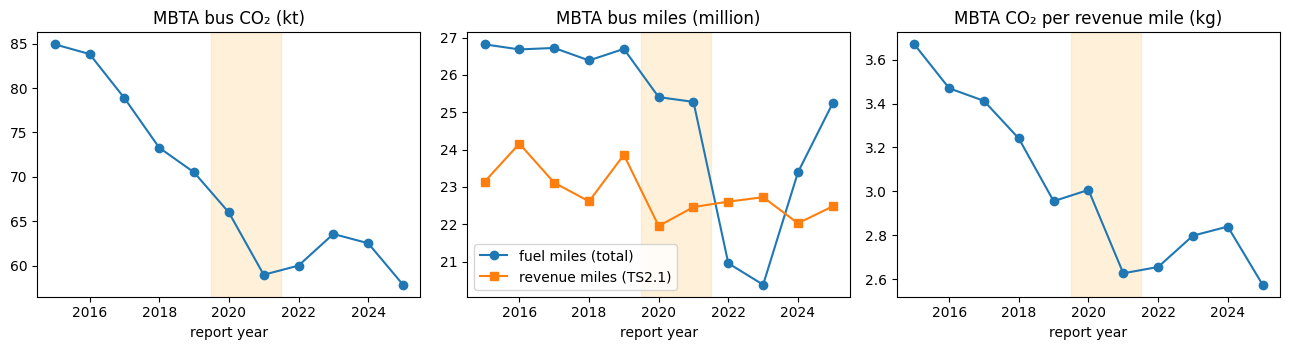

In [10]:
mbta = panel[panel.ntd_id == "10003"].set_index("report_year")[
    ["modes", "diesel_gal", "cng_gal", "elec_batt_kwh", "elec_prop_kwh", "biodiesel_gal", "co2_t", "fuel_miles", "vrm", "intensity_kg_vrm", "active_buses", "avg_age", "share_hybrid", "share_cng", "share_bev"]]
print(mbta.round(3).to_string())
mbta.to_csv(OUT / "mbta_history.csv")
print("MBTA trolleybus (TB) rows:", fe[(fe.ntd_id == "10003") & (fe["mode"] == "TB")][["report_year", "elec_prop_kwh"]].values.tolist())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
(mbta.co2_t / 1e3).plot(ax=axes[0], marker="o"); axes[0].set_title("MBTA bus CO₂ (kt)")
(mbta.fuel_miles / 1e6).plot(ax=axes[1], marker="o", label="fuel miles (total)")
(mbta.vrm / 1e6).plot(ax=axes[1], marker="s", label="revenue miles (TS2.1)"); axes[1].legend(); axes[1].set_title("MBTA bus miles (million)")
mbta.intensity_kg_vrm.plot(ax=axes[2], marker="o"); axes[2].set_title("MBTA CO₂ per revenue mile (kg)")
for a in axes: a.axvspan(2019.5, 2021.5, color="orange", alpha=.15); a.set_xlabel("report year")
savefig(fig, "04_mbta")

**MBTA miles by fuel.** Why do MBTA's fuel-table miles fall below its revenue miles in 2022–2023?

In [11]:
mm = fe[(fe.ntd_id == "10003") & fe["mode"].isin(["MB", "RB"]) & fe.report_year.between(2020, 2025)]
print(mm.groupby("report_year")[[c for c in miles_cols if mm[c].fillna(0).sum() > 0]].sum().astype(int).to_string())

             miles_diesel  miles_gasoline  miles_cng  miles_other  miles_elec_batt
report_year                                                                       
2020             20095697          172543    4029303      1083935            24913
2021             20050316          123405    3995027      1053546            56221
2022             17107108           64194    3732369            0            50769
2023             16314369           65700    3950032            0            50984
2024             19661982           61085    3661463            0             7382
2025             21576029           70328    3592234            0             9630


## 7. Commuter bus (CB) and the backtest windows this allows

In [12]:
cb_f = cb[cb.has_fuel]
print("CB agencies with fuel:", cb_f.ntd_id.nunique(), "| CB share of bus+CB CO2 (2025):",
      round(cb_f.query("report_year==2025").co2_t.sum() / (cb_f.query("report_year==2025").co2_t.sum() + bus_f.query("report_year==2025").co2_t.sum()), 3))
# rolling-origin windows: train on years <= T, forecast T+h; need >= 3 training years
for h in (1, 2, 3):
    origins = [t for t in YEARS if t - min(YEARS) + 1 >= 3 and t + h <= max(YEARS)]
    no_covid = [t for t in origins if not ({t + h} & {2020, 2021})]
    print(f"horizon {h}: {len(origins)} origins {origins[0]}..{origins[-1]}; targets outside 2020-21: {len(no_covid)}")

CB agencies with fuel: 119 | CB share of bus+CB CO2 (2025): 0.043
horizon 1: 8 origins 2017..2024; targets outside 2020-21: 6
horizon 2: 7 origins 2017..2023; targets outside 2020-21: 5
horizon 3: 6 origins 2017..2022; targets outside 2020-21: 4


## 8. Summary for the go/no-go

In [13]:
summary = {
    "fuel_years_on_disk": f"{min(YEARS)}–{max(YEARS)} ({len(YEARS)} report years)",
    "bus_agencies_with_any_fuel": int(per_agency.shape[0]),
    "agencies_ge7_years": int((per_agency.n_years >= 7).sum()),
    "agencies_ge7_unbroken": int((per_agency.longest_run >= 7).sum()),
    "agencies_all_11_years": int((per_agency.n_years == 11).sum()),
    "usable_agency_years": int(len(usable)),
    "usable_agencies": int(per_usable.size),
    "usable_agencies_ge7_years": int((per_usable >= 7).sum()),
}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1)
summary

{'fuel_years_on_disk': '2015–2025 (11 report years)',
 'bus_agencies_with_any_fuel': 478,
 'agencies_ge7_years': 409,
 'agencies_ge7_unbroken': 403,
 'agencies_all_11_years': 363,
 'usable_agency_years': 4403,
 'usable_agencies': 456,
 'usable_agencies_ge7_years': 393}